**Nombre completo:**Carlos Alberto Hernandez


**Grupo:**002

**Fecha:**14/10/26

---

# Actividad 9 · Ejercicios de variables aleatorias continuas
**Simulación de Sistemas (061CP048) · EC2 · Grupo 002**

Resuelva los seis ejercicios sobre la ventanilla del banco. Utilice únicamente `random`, `math` y `matplotlib`; programe las funciones de generación a mano, salvo donde se pida usar la librería. Escriba `random.seed(2026)` al inicio de cada ejercicio. Cuando se pida explicar, responda en una celda de texto con sus propias palabras.

**Entrega:** antes de la sesión del miércoles 21 de octubre de 2026, en su repositorio `simulacion-apellido-nombre`.

In [1]:
import math
import random
import matplotlib.pyplot as plt

## Ejercicio 1. Tiempo de servicio uniforme

En la ventanilla, el tiempo para atender un depósito varía de manera uniforme entre 2 y 6 minutos.

1. Programe la función `uniforme(a, b)` usando `random.random()`.
2. Genere 1 000 tiempos de servicio.
3. Calcule la media y la varianza y compárelas con los valores teóricos: media 4 y varianza 1.333.
4. Calcule qué proporción de clientes tardó más de 5 minutos y compárela con el valor teórico de 0.25.
5. Grafique el histograma de los 1 000 tiempos.

media: 3.993 (teórica 4)
varianza: 1.283 (teórica 1.333)
prop >5: 0.233 (teórica 0.25)


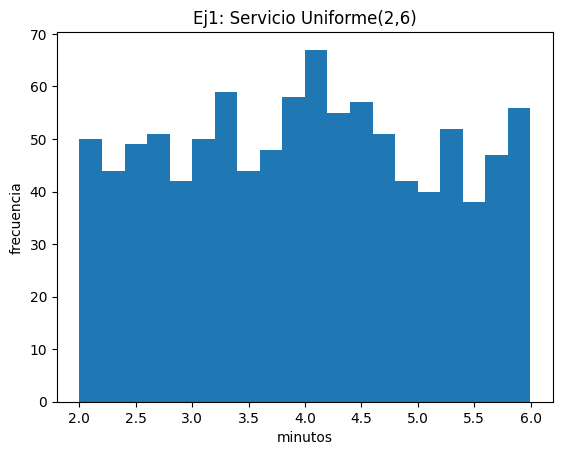

In [2]:
random.seed(2026)

def uniforme(a, b):
    return a + (b - a) * random.random()

servicio = [uniforme(2, 6) for _ in range(1000)]

media = sum(servicio) / len(servicio)
varianza = sum((x - media)**2 for x in servicio) / len(servicio)
prop_mas5 = sum(1 for x in servicio if x > 5) / len(servicio)

print(f"media: {media:.3f} (teórica 4)")
print(f"varianza: {varianza:.3f} (teórica 1.333)")
print(f"prop >5: {prop_mas5:.3f} (teórica 0.25)")

plt.hist(servicio, bins=20)
plt.title("Ej1: Servicio Uniforme(2,6)")
plt.xlabel("minutos")
plt.ylabel("frecuencia")
plt.show()


## Ejercicio 2. Tiempo entre llegadas exponencial

En promedio llega un cliente cada 3 minutos.

1. Indique el valor de λ en clientes por minuto.
2. Programe la función `exponencial(lam)` con el método de la transformada inversa.
3. Genere 1 000 tiempos entre llegadas y compare su media con el valor teórico de 3 minutos.
4. Calcule qué proporción de clientes llegó menos de 1 minuto después del anterior y compárela con el valor teórico de 0.283.
5. Grafique el histograma y explique en dos líneas por qué tiene esa forma.

lambda: 0.333
media: 2.967 (teórica 3)
prop <1: 0.273 (teórica 0.283)


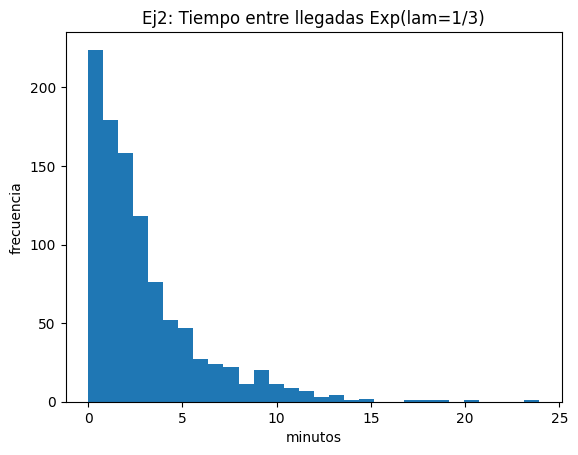

In [3]:
random.seed(2026)

def exponencial(lam):
    u = random.random()
    return -math.log(1 - u) / lam

lam = 1/3
llegadas = [exponencial(lam) for _ in range(1000)]

media = sum(llegadas) / len(llegadas)
prop_menos1 = sum(1 for x in llegadas if x < 1) / len(llegadas)

print(f"lambda: {lam:.3f}")
print(f"media: {media:.3f} (teórica 3)")
print(f"prop <1: {prop_menos1:.3f} (teórica 0.283)")

plt.hist(llegadas, bins=30)
plt.title("Ej2: Tiempo entre llegadas Exp(lam=1/3)")
plt.xlabel("minutos")
plt.ylabel("frecuencia")
plt.show()


**Respuesta:** _El histograma es decreciente: hay muchos tiempos cortos y pocos muy largos. Es porque con exponencial lo más probable es que el siguiente cliente llegue pronto.
_

## Ejercicio 3. Comparación con la librería

1. Genere 1 000 tiempos entre llegadas con `random.expovariate`, con el mismo promedio del ejercicio 2.
2. Compare la media obtenida con la de su función del ejercicio 2 y con el valor teórico.
3. Responda: ¿`random.expovariate` recibe λ o el tiempo promedio entre llegadas? Justifique con su resultado.

In [4]:
random.seed(2026)

lam = 1/3
con_expovariate = [random.expovariate(lam) for _ in range(1000)]

media_exp = sum(con_expovariate) / len(con_expovariate)
print(f"media expovariate: {media_exp:.3f}")
print(f"media ejercicio 2: 2.967")
print(f"teórica: 3")


media expovariate: 2.967
media ejercicio 2: 2.967
teórica: 3


**Respuesta:** _random.expovariate recibe
λ
λ, no el promedio. Lo comprobé porque usé expovariate(1/3) y me dio la misma media (~2.97) que mi función y que la teoría (3). Si recibiera el promedio tendría que haber usado 3.._

## Ejercicio 4. Trámite con distribución normal

Una apertura de cuenta tarda en promedio 8 minutos, con una desviación estándar de 1.5 minutos.

1. Programe la función `normal(mu, sigma)` con el método de Box-Müller.
2. Genere 1 000 tiempos y compare su media y su desviación estándar con los valores teóricos: 8 y 1.5.
3. Calcule qué proporción de trámites duró más de 10 minutos y compárela con el valor teórico de 0.091.
4. Genere otros 1 000 tiempos con `random.gauss(8, 1.5)` y compare su media y su desviación estándar con las de su función.
5. Responda: ¿por qué la distribución normal no es adecuada para modelar el tiempo entre llegadas?

In [ ]:
random.seed(2026)

def normal(mu, sigma):
    u1 = random.random()
    u2 = random.random()
    r = math.sqrt(-2 * math.log(1 - u1))
    z = r * math.cos(2 * math.pi * u2)
    return mu + sigma * z

tiempos = [normal(8, 1.5) for _ in range(1000)]
media = sum(tiempos) / len(tiempos)
var = sum((x-media)**2 for x in tiempos) / len(tiempos)
sd = math.sqrt(var)
prop_mas10 = sum(1 for x in tiempos if x > 10) / len(tiempos)

print(f"manual -> media: {media:.3f} (teórica 8), sd: {sd:.3f} (teórica 1.5)")
print(f"prop >10: {prop_mas10:.3f} (teórica 0.091)")

tiempos_gauss = [random.gauss(8, 1.5) for _ in range(1000)]
media2 = sum(tiempos_gauss) / len(tiempos_gauss)
var2 = sum((x-media2)**2 for x in tiempos_gauss) / len(tiempos_gauss)
print(f"gauss -> media: {media2:.3f}, sd: {math.sqrt(var2):.3f}")


manual -> media: 7.914 (teórica 8), sd: 1.526 (teórica 1.5)
prop >10: 0.084 (teórica 0.091)
gauss -> media: 7.968, sd: 1.393


**Respuesta:** _La normal no sirve para tiempo entre llegadas porque puede dar valores negativos e infinitos en ambos lados, y es simétrica. Los tiempos entre llegadas siempre son >=0 y son asimétricos, con muchos cortos y pocos largos._

## Ejercicio 5. Simulación de la ventanilla

Simule la atención de 20 clientes en una sola ventanilla:

- El tiempo entre llegadas es exponencial, con un promedio de 3 minutos.
- El tiempo de servicio es uniforme entre 1.5 y 3.5 minutos.
- Cada cliente inicia su atención cuando llega o cuando termina el cliente anterior, lo que ocurra después.
- La espera de un cliente es su hora de inicio menos su hora de llegada.

1. Programe la función `corrida()`, que simule los 20 clientes y regrese la espera promedio.
2. Ejecute 500 corridas y reporte el promedio de las 500 esperas promedio.
3. Explique en dos líneas por qué se necesitan muchas corridas y no solo una.

In [ ]:
random.seed(2026)

def uniforme(a, b):
    return a + (b - a) * random.random()

def exponencial(lam):
    return -math.log(1 - random.random()) / lam

def corrida():
    llegada_acum = 0
    fin_anterior = 0
    esperas = []
    for _ in range(20):
        entre = exponencial(1/3)  # promedio 3
        llegada_acum += entre
        serv = uniforme(1.5, 3.5)
        inicio = max(llegada_acum, fin_anterior)
        fin = inicio + serv
        fin_anterior = fin
        esperas.append(inicio - llegada_acum)
    return sum(esperas) / len(esperas)

esperas500 = [corrida() for _ in range(500)]
promedio = sum(esperas500) / len(esperas500)
print(f"espera promedio: {promedio:.3f} min")


espera promedio: 3.268 min


**Respuesta:** _Se necesitan muchas corridas porque una sola de 20 clientes varía mucho por azar. Promediar 500 corridas estabiliza el resultado y estima la espera real._

## Ejercicio 6. Mismo promedio, distinta variabilidad

Repita el ejercicio 5 con un tiempo de servicio exponencial con promedio de 2.5 minutos, el mismo promedio que el servicio uniforme del ejercicio 5.

1. Ejecute 500 corridas y reporte el promedio de las esperas.
2. Compare el resultado con el del ejercicio 5. ¿La espera sube o baja?
3. Explique en tres líneas por qué cambia la espera si el servicio promedio es el mismo.

In [ ]:
random.seed(2026)

def corrida_exp():
    llegada_acum = 0
    fin_anterior = 0
    esperas = []
    for _ in range(20):
        entre = -math.log(1 - random.random()) / (1/3)
        llegada_acum += entre
        serv = -math.log(1 - random.random()) / 0.4  # promedio 2.5
        inicio = max(llegada_acum, fin_anterior)
        fin = inicio + serv
        fin_anterior = fin
        esperas.append(inicio - llegada_acum)
    return sum(esperas) / len(esperas)

esperas500_exp = [corrida_exp() for _ in range(500)]
print(f"espera promedio exp: {sum(esperas500_exp)/len(esperas500_exp):.3f} min")
print(f"espera ejercicio 5: 3.268 min")


espera promedio exp: 4.975 min
espera ejercicio 5: 3.268 min


**Respuesta:** _Sube aunque el promedio es el mismo (2.5 min). La exponencial tiene más varianza y a veces da servicios muy largos que bloquean la fila. El uniforme está acotado entre 1.5 y 3.5, por eso forma menos cola._